In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [12]:
df = pd.read_csv("Instagram data.csv", encoding="latin1")
df

,Impressions,From Home,From Hashtags,From Explore,From Other,Saves,Comments,Shares,Likes,Profile Visits,Follows,Caption,Hashtags
0,3920,2586,1028,619,56,98,9,5,162,35,2,Here are some of the most important data visua...,#finance #money #business #investing #investme...
1,5394,2727,1838,1174,78,194,7,14,224,48,10,Here are some of the best data science project...,#healthcare #health #covid #data #datascience ...
2,4021,2085,1188,0,533,41,11,1,131,62,12,Learn how to train a machine learning model an...,#data #datascience #dataanalysis #dataanalytic...
3,4528,2700,621,932,73,172,10,7,213,23,8,Heres how you can write a Python program to d...,#python #pythonprogramming #pythonprojects #py...
4,2518,1704,255,279,37,96,5,4,123,8,0,Plotting annotations while visualizing your da...,#datavisualization #datascience #data #dataana...
...,...,...,...,...,...,...,...,...,...,...,...,...,...
114,13700,5185,3041,5352,77,573,2,38,373,73,80,Here are some of the best data science certifi...,#datascience #datasciencejobs #datasciencetrai...
115,5731,1923,1368,2266,65,135,4,1,148,20,18,Clustering is a machine learning technique use...,#machinelearning #machinelearningalgorithms #d...
116,4139,1133,1538,1367,33,36,0,1,92,34,10,Clustering music genres is a task of grouping ...,#machinelearning #machinelearningalgorithms #d...
117,32695,11815,3147,17414,170,1095,2,75,549,148,214,Here are some of the best data science certifi...,#datascience #datasciencejobs #datasciencetrai...


In [13]:
df.head()

,Impressions,From Home,From Hashtags,From Explore,From Other,Saves,Comments,Shares,Likes,Profile Visits,Follows,Caption,Hashtags
0,3920,2586,1028,619,56,98,9,5,162,35,2,Here are some of the most important data visua...,#finance #money #business #investing #investme...
1,5394,2727,1838,1174,78,194,7,14,224,48,10,Here are some of the best data science project...,#healthcare #health #covid #data #datascience ...
2,4021,2085,1188,0,533,41,11,1,131,62,12,Learn how to train a machine learning model an...,#data #datascience #dataanalysis #dataanalytic...
3,4528,2700,621,932,73,172,10,7,213,23,8,Heres how you can write a Python program to d...,#python #pythonprogramming #pythonprojects #py...
4,2518,1704,255,279,37,96,5,4,123,8,0,Plotting annotations while visualizing your da...,#datavisualization #datascience #data #dataana...


In [14]:
df.tail()

,Impressions,From Home,From Hashtags,From Explore,From Other,Saves,Comments,Shares,Likes,Profile Visits,Follows,Caption,Hashtags
114,13700,5185,3041,5352,77,573,2,38,373,73,80,Here are some of the best data science certifi...,#datascience #datasciencejobs #datasciencetrai...
115,5731,1923,1368,2266,65,135,4,1,148,20,18,Clustering is a machine learning technique use...,#machinelearning #machinelearningalgorithms #d...
116,4139,1133,1538,1367,33,36,0,1,92,34,10,Clustering music genres is a task of grouping ...,#machinelearning #machinelearningalgorithms #d...
117,32695,11815,3147,17414,170,1095,2,75,549,148,214,Here are some of the best data science certifi...,#datascience #datasciencejobs #datasciencetrai...
118,36919,13473,4176,16444,2547,653,5,26,443,611,228,175 Python Projects with Source Code solved an...,#python #pythonprogramming #pythonprojects #py...


In [15]:
df.columns

Index(['Impressions', 'From Home', 'From Hashtags', 'From Explore',
       'From Other', 'Saves', 'Comments', 'Shares', 'Likes', 'Profile Visits',
       'Follows', 'Caption', 'Hashtags'],
      dtype='object')

In [16]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119 entries, 0 to 118
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   Impressions     119 non-null    int64 
 1   From Home       119 non-null    int64 
 2   From Hashtags   119 non-null    int64 
 3   From Explore    119 non-null    int64 
 4   From Other      119 non-null    int64 
 5   Saves           119 non-null    int64 
 6   Comments        119 non-null    int64 
 7   Shares          119 non-null    int64 
 8   Likes           119 non-null    int64 
 9   Profile Visits  119 non-null    int64 
 10  Follows         119 non-null    int64 
 11  Caption         119 non-null    object
 12  Hashtags        119 non-null    object
dtypes: int64(11), object(2)
memory usage: 12.2+ KB


In [17]:
df.describe()

,Impressions,From Home,From Hashtags,From Explore,From Other,Saves,Comments,Shares,Likes,Profile Visits,Follows
count,119.000000,119.000000,119.000000,119.000000,119.000000,119.000000,119.000000,119.000000,119.000000,119.000000,119.000000
mean,5703.991597,2475.789916,1887.512605,1078.100840,171.092437,153.310924,6.663866,9.361345,173.781513,50.621849,20.756303
std,4843.780105,1489.386348,1884.361443,2613.026132,289.431031,156.317731,3.544576,10.089205,82.378947,87.088402,40.921580
min,1941.000000,1133.000000,116.000000,0.000000,9.000000,22.000000,0.000000,0.000000,72.000000,4.000000,0.000000
25%,3467.000000,1945.000000,726.000000,157.500000,38.000000,65.000000,4.000000,3.000000,121.500000,15.000000,4.000000
50%,4289.000000,2207.000000,1278.000000,326.000000,74.000000,109.000000,6.000000,6.000000,151.000000,23.000000,8.000000
75%,6138.000000,2602.500000,2363.500000,689.500000,196.000000,169.000000,8.000000,13.500000,204.000000,42.000000,18.000000
max,36919.000000,13473.000000,11817.000000,17414.000000,2547.000000,1095.000000,19.000000,75.000000,549.000000,611.000000,260.000000


In [18]:
df.isnull().sum()

Impressions       0
From Home         0
From Hashtags     0
From Explore      0
From Other        0
Saves             0
Comments          0
Shares            0
Likes             0
Profile Visits    0
Follows           0
Caption           0
Hashtags          0
dtype: int64

In [19]:
df.dropna(inplace=True)

In [20]:
df.duplicated().sum()

np.int64(17)

In [21]:
df.drop_duplicates(inplace=True)

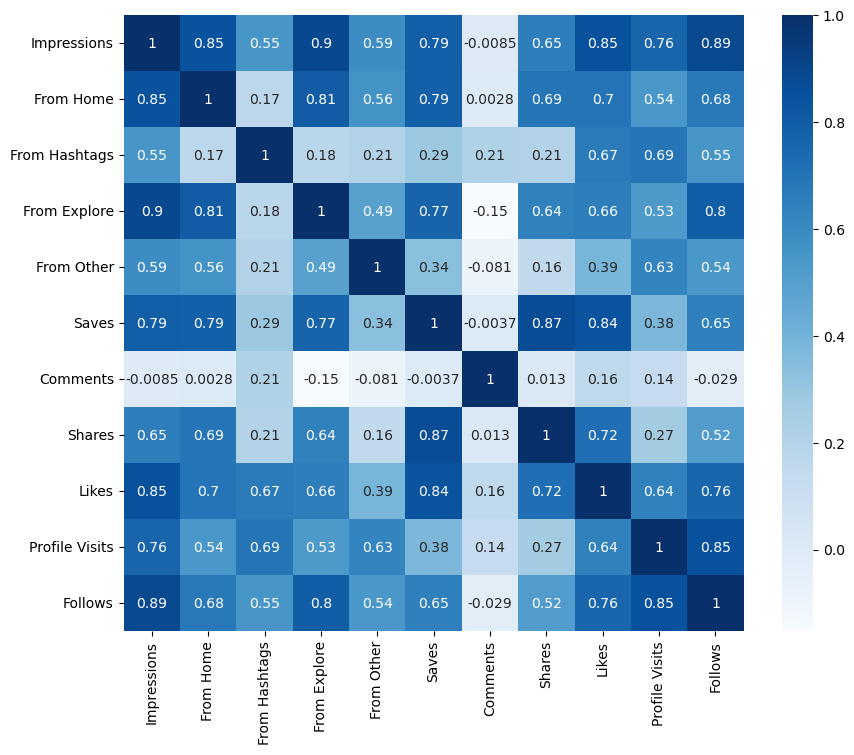

In [22]:
numeric_df = df.select_dtypes(include=np.number)

plt.figure(figsize=(10,8))
sns.heatmap(numeric_df.corr(), annot=True, cmap="Blues")
plt.show()

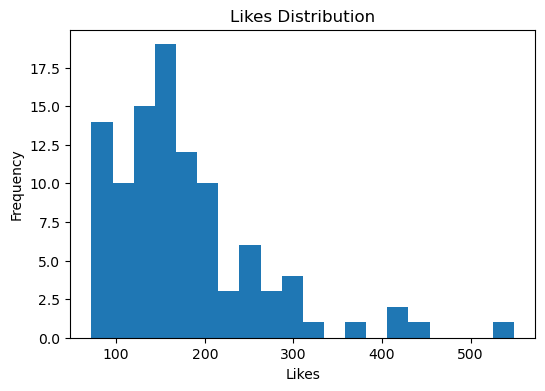

In [23]:
plt.figure(figsize=(6,4))
plt.hist(df["Likes"], bins=20)
plt.title("Likes Distribution")
plt.xlabel("Likes")
plt.ylabel("Frequency")
plt.show()

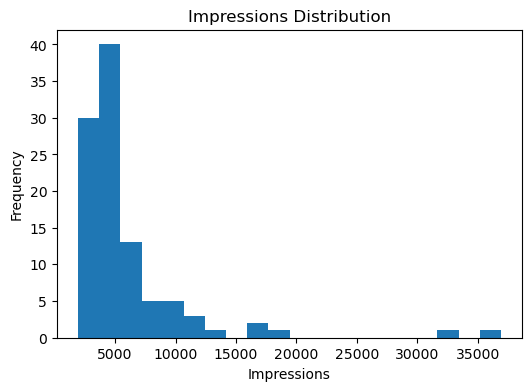

In [24]:
plt.figure(figsize=(6,4))
plt.hist(df["Impressions"], bins=20)
plt.title("Impressions Distribution")
plt.xlabel("Impressions")
plt.ylabel("Frequency")
plt.show()

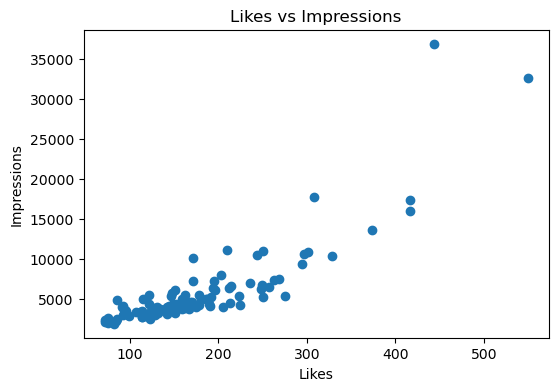

In [25]:
plt.figure(figsize=(6,4))
plt.scatter(df["Likes"], df["Impressions"])
plt.xlabel("Likes")
plt.ylabel("Impressions")
plt.title("Likes vs Impressions")
plt.show()

In [26]:
X = df[[
    "Likes",
    "Comments",
    "Shares",
    "Saves",
    "Profile Visits",
    "Follows"
]]
# X
y = df["Impressions"]
# y

In [27]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [28]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()

model.fit(X_train, y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [29]:
y_pred = model.predict(X_test)

In [30]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

print("MAE :", mean_absolute_error(y_test, y_pred))
print("MSE :", mean_squared_error(y_test, y_pred))
print("RMSE :", np.sqrt(mean_squared_error(y_test, y_pred)))
print("R2 Score :", r2_score(y_test, y_pred))

MAE : 1928.9224259817586
MSE : 12597650.025740668
RMSE : 3549.3168393002993
R2 Score : 0.7445217072176533


In [31]:
result = pd.DataFrame({
    "Actual": y_test,
    "Predicted": y_pred
})

result

,Actual,Predicted
30,6666,6134.382966
67,10933,15930.378040
62,4239,5158.829794
47,2826,3603.185704
42,4289,4636.973260
40,16062,18473.556915
107,17396,31510.510742
45,4298,5556.105577
10,2218,2432.487157
0,3920,3786.728347


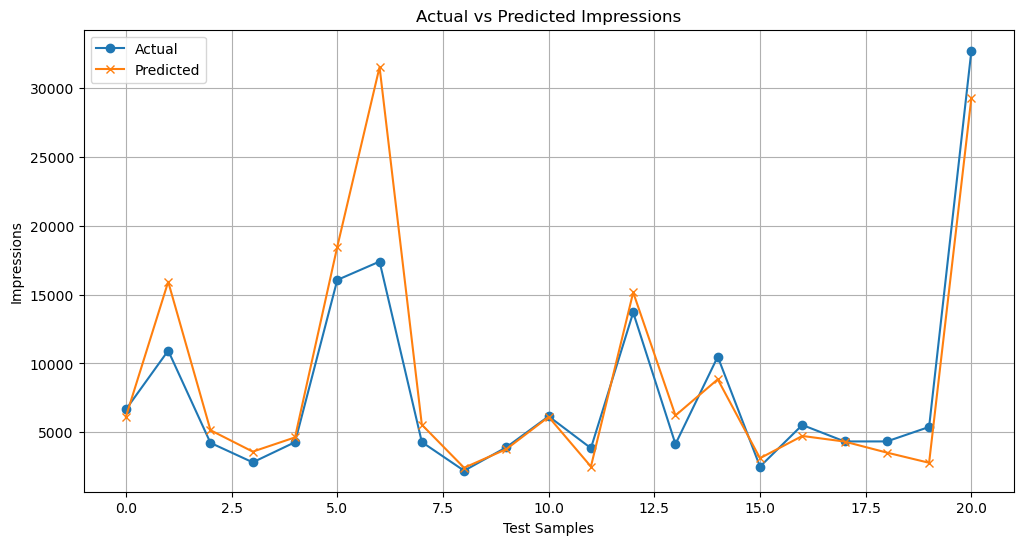

In [32]:
plt.figure(figsize=(12,6))

plt.plot(y_test.values, label="Actual", marker='o')
plt.plot(y_pred, label="Predicted", marker='x')

plt.title("Actual vs Predicted Impressions")
plt.xlabel("Test Samples")
plt.ylabel("Impressions")
plt.legend()
plt.grid(True)

plt.show()

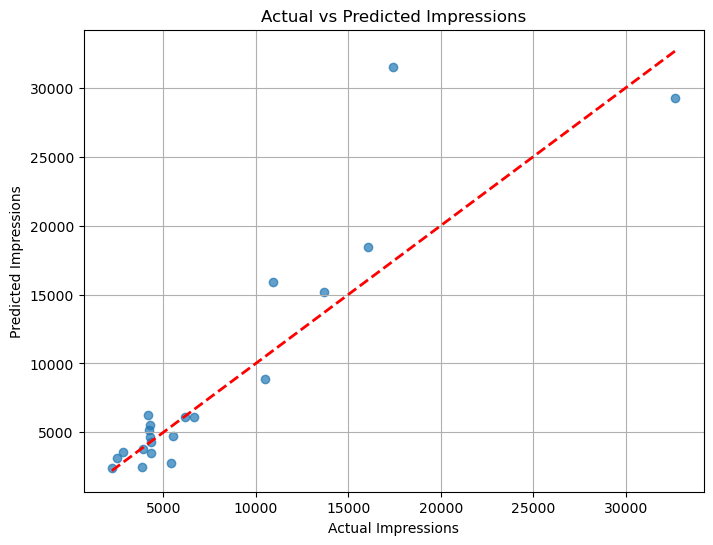

In [33]:
plt.figure(figsize=(8,6))

plt.scatter(y_test, y_pred, alpha=0.7)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    'r--',
    linewidth=2
)

plt.xlabel("Actual Impressions")
plt.ylabel("Predicted Impressions")
plt.title("Actual vs Predicted Impressions")
plt.grid(True)

plt.show()

In [34]:
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures

In [35]:
poly=PolynomialFeatures(degree=2)

X_train_poly=poly.fit_transform(X_train)

X_test_poly=poly.transform(X_test)

In [36]:
poly_model=LinearRegression()

poly_model.fit(X_train_poly, y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [37]:
y_pred_poly=poly_model.predict(X_test_poly)


In [38]:
print("Polynomial Regression")

print("MAE :",mean_absolute_error(y_test,y_pred_poly))

print("MSE :",mean_squared_error(y_test,y_pred_poly))

print("RMSE :",np.sqrt(mean_squared_error(y_test,y_pred_poly)))

print("R2 Score :",r2_score(y_test,y_pred_poly))

Polynomial Regression
MAE : 1756.84263271844
MSE : 9218910.17182897
RMSE : 3036.265826937584
R2 Score : 0.8130420017066475


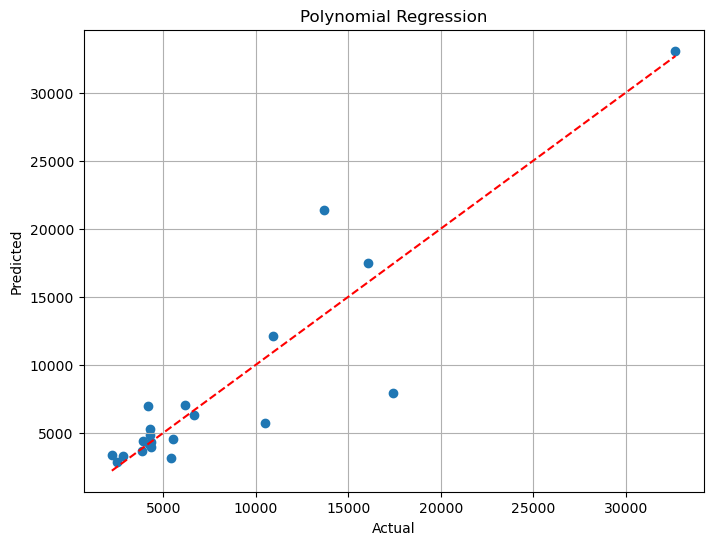

In [39]:
plt.figure(figsize=(8,6))

plt.scatter(y_test,y_pred_poly)

plt.plot(
[y_test.min(),y_test.max()],
[y_test.min(),y_test.max()],
'r--'
)

plt.xlabel("Actual")

plt.ylabel("Predicted")

plt.title("Polynomial Regression")

plt.grid(True)

plt.show()

In [40]:
print("Linear Regression R2 :",r2_score(y_test,y_pred))

print("Polynomial Regression R2 :",r2_score(y_test,y_pred_poly))

Linear Regression R2 : 0.7445217072176533
Polynomial Regression R2 : 0.8130420017066475


In [41]:
new_data = [[
    500,   # Likes
    45,    # Comments
    20,    # Shares
    60,    # Saves
    300,   # Profile Visits
    25     # Follows
]]

prediction = model.predict(new_data)

print("Predicted Impressions =", prediction[0])

Predicted Impressions = 9500.640596095142


C:\Users\ASUS\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


In [ ]:
likes = float(input("Enter Likes: "))
comments = float(input("Enter Comments: "))
shares = float(input("Enter Shares: "))
saves = float(input("Enter Saves: "))
profile_visits = float(input("Enter Profile Visits: "))
follows = float(input("Enter Follows: "))

new_data = [[likes, comments, shares, saves, profile_visits, follows]]

new_data_poly = poly.transform(new_data)

prediction = poly_model.predict(new_data_poly)

print("Predicted Impressions =", prediction[0])